# AIoT HW2：WHO 各國平均壽命預測 — 多元線性回歸（CRISP-DM）

- **資料集**：Life Expectancy (WHO) — Kaggle，作者 KumarRajarshi
  <https://www.kaggle.com/datasets/kumarajarshi/life-expectancy-who>
- **規模**：2,938 筆 × 22 欄（193 國、2000–2015 年），扣除目標與國名後有 **20 個特徵**（符合 >13 的要求）
- **方法**：多元線性回歸（OLS）＋ 5 種特徵選擇方法比較 ＋ Ridge / Lasso ＋ 95% 信賴區間 / 預測區間 ＋ 五大回歸假設檢驗
- **兩個問題（Problem）**
  - **Problem 1**：預測一國當年的 **平均壽命（Life expectancy）**
  - **Problem 2**：預測一國當年的 **成人死亡率（Adult Mortality，15–60 歲每千人死亡數）**

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan, linear_rainbow
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from sklearn.feature_selection import RFE, f_regression
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV, lasso_path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
EARTH = ["#8c6240", "#7d8f5a", "#c9923f", "#a8442f", "#5f6f73"]
sns.set_theme(style="whitegrid", palette=EARTH)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "Life Expectancy Data.csv"
ASSETS = ROOT / "assets"
MODEL_DIR = ROOT / "model"
ASSETS.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)
SEED = 42

## 1. Business Understanding（商業理解）

平均壽命是衡量一個國家整體健康與發展程度最常用的指標。WHO 與各國衛生單位需要知道：

1. **哪些因素**（疫苗覆蓋率、HIV、教育、經濟、死亡率…）與平均壽命的關係最強？
2. 在給定一國的健康與社經指標時，**能否預測其平均壽命**，並給出**不確定性範圍**（預測區間）？

| 項目 | Problem 1 | Problem 2 |
|---|---|---|
| 目標 (y) | 平均壽命（歲） | 成人死亡率（每千人） |
| 候選特徵 | 20 個 | 19 個（排除平均壽命，避免目標洩漏） |
| 成功標準 | 測試集 R² ≥ 0.80、RMSE < 4 歲 | 作為對照問題，觀察線性模型在雜訊較大目標上的表現 |
| 應用情境 | 政策模擬：調整疫苗率、教育年數等，觀察預期壽命變化 | 找出成人死亡率的主要驅動因子 |

**評估方式**：MAE、MSE、RMSE、R²、Adjusted R²；95% 預測區間的實際覆蓋率；五大回歸假設檢驗。

## 2. Data Understanding（資料理解）

In [2]:
raw = pd.read_csv(DATA)
raw.columns = [c.strip() for c in raw.columns]  # 原始欄名有多餘空白，例如 "Life expectancy "
print("shape:", raw.shape)
print("國家數:", raw["Country"].nunique(), "| 年份:", raw["Year"].min(), "–", raw["Year"].max())
raw.head()

shape: (2938, 22)
國家數: 193 | 年份: 2000 – 2015


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,19.1,83,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,18.6,86,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,18.1,89,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,17.6,93,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,17.2,97,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [3]:
RENAME = {
    "Country": "country", "Year": "year", "Status": "status",
    "Life expectancy": "life_expectancy", "Adult Mortality": "adult_mortality",
    "infant deaths": "infant_deaths", "Alcohol": "alcohol",
    "percentage expenditure": "pct_expenditure", "Hepatitis B": "hepatitis_b",
    "Measles": "measles", "BMI": "bmi", "under-five deaths": "under_five_deaths",
    "Polio": "polio", "Total expenditure": "total_expenditure", "Diphtheria": "diphtheria",
    "HIV/AIDS": "hiv_aids", "GDP": "gdp", "Population": "population",
    "thinness  1-19 years": "thinness_10_19", "thinness 5-9 years": "thinness_5_9",
    "Income composition of resources": "income_composition", "Schooling": "schooling",
}
LABELS = {
    "life_expectancy": "平均壽命 (歲)",
    "adult_mortality": "成人死亡率 (每千人, 15–60歲)",
    "year": "年份",
    "developed": "已開發國家 (1=是)",
    "infant_deaths": "嬰兒死亡數 (每千人口)",
    "alcohol": "人均酒精消費 (公升)",
    "pct_expenditure": "醫療支出佔人均GDP (%)",
    "hepatitis_b": "B肝疫苗覆蓋率 (%)",
    "measles": "麻疹通報數 (每千人口)",
    "bmi": "平均 BMI",
    "under_five_deaths": "五歲以下死亡數 (每千人口)",
    "polio": "小兒麻痺疫苗覆蓋率 (%)",
    "total_expenditure": "政府醫療支出佔總支出 (%)",
    "diphtheria": "白喉疫苗覆蓋率 (%)",
    "hiv_aids": "HIV/AIDS 死亡 (每千活產, 0–4歲)",
    "gdp": "人均 GDP (USD)",
    "population": "人口",
    "thinness_10_19": "10–19歲消瘦盛行率 (%)",
    "thinness_5_9": "5–9歲消瘦盛行率 (%)",
    "income_composition": "人類發展指數-收入組成 (0–1)",
    "schooling": "受教育年數",
}
df0 = raw.rename(columns=RENAME)
info = pd.DataFrame({
    "dtype": df0.dtypes.astype(str),
    "missing": df0.isna().sum(),
    "missing_%": (df0.isna().mean() * 100).round(1),
    "n_unique": df0.nunique(),
})
info

,dtype,missing,missing_%,n_unique
country,str,0,0.0,193
year,int64,0,0.0,16
status,str,0,0.0,2
life_expectancy,float64,10,0.3,362
adult_mortality,float64,10,0.3,425
infant_deaths,int64,0,0.0,209
alcohol,float64,194,6.6,1076
pct_expenditure,float64,0,0.0,2328
hepatitis_b,float64,553,18.8,87
measles,int64,0,0.0,958


In [4]:
df0.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
year,2938.0,2007.52,4.61,2000.00,2004.00,2008.00,2012.00,2.015000e+03
life_expectancy,2928.0,69.22,9.52,36.30,63.10,72.10,75.70,8.900000e+01
adult_mortality,2928.0,164.80,124.29,1.00,74.00,144.00,228.00,7.230000e+02
infant_deaths,2938.0,30.30,117.93,0.00,0.00,3.00,22.00,1.800000e+03
alcohol,2744.0,4.60,4.05,0.01,0.88,3.76,7.70,1.787000e+01
pct_expenditure,2938.0,738.25,1987.91,0.00,4.69,64.91,441.53,1.947991e+04
hepatitis_b,2385.0,80.94,25.07,1.00,77.00,92.00,97.00,9.900000e+01
measles,2938.0,2419.59,11467.27,0.00,0.00,17.00,360.25,2.121830e+05
bmi,2904.0,38.32,20.04,1.00,19.30,43.50,56.20,8.730000e+01
under_five_deaths,2938.0,42.04,160.45,0.00,0.00,4.00,28.00,2.500000e+03


**觀察到的資料品質問題**

- `income_composition`（HDI 收入組成）與 `schooling` 出現 **0**，實際上不可能為 0 → 視為缺值代碼。
- `population`、`measles`、`infant_deaths`、`under_five_deaths`、`pct_expenditure`、`gdp`、`hiv_aids` 嚴重右偏（偏態 > 3），需做 log 轉換。
- `bmi` 有大量 < 10 或 > 60 的不合理值（此資料集已知的品質問題），保留但在特徵選擇中由資料決定是否使用。
- 這是 **panel data**（同一國家 16 年），隨機切分會讓同一國家同時出現在訓練與測試集 → 造成資訊洩漏，因此改以 **國家為單位分組切分**。

In [5]:
num = df0.select_dtypes("number")
quality = pd.DataFrame({
    "skew": num.skew().round(2),
    "zeros": (num == 0).sum(),
})
print("income_composition == 0:", (df0.income_composition == 0).sum(),
      "| schooling == 0:", (df0.schooling == 0).sum(),
      "| bmi < 10:", (df0.bmi < 10).sum())
quality.sort_values("skew", ascending=False)

income_composition == 0: 130 | schooling == 0: 28 | bmi < 10: 283


,skew,zeros
population,15.92,0
infant_deaths,9.79,848
under_five_deaths,9.50,785
measles,9.44,983
hiv_aids,5.40,0
pct_expenditure,4.65,611
gdp,3.21,0
thinness_5_9,1.78,0
thinness_10_19,1.71,0
adult_mortality,1.17,0


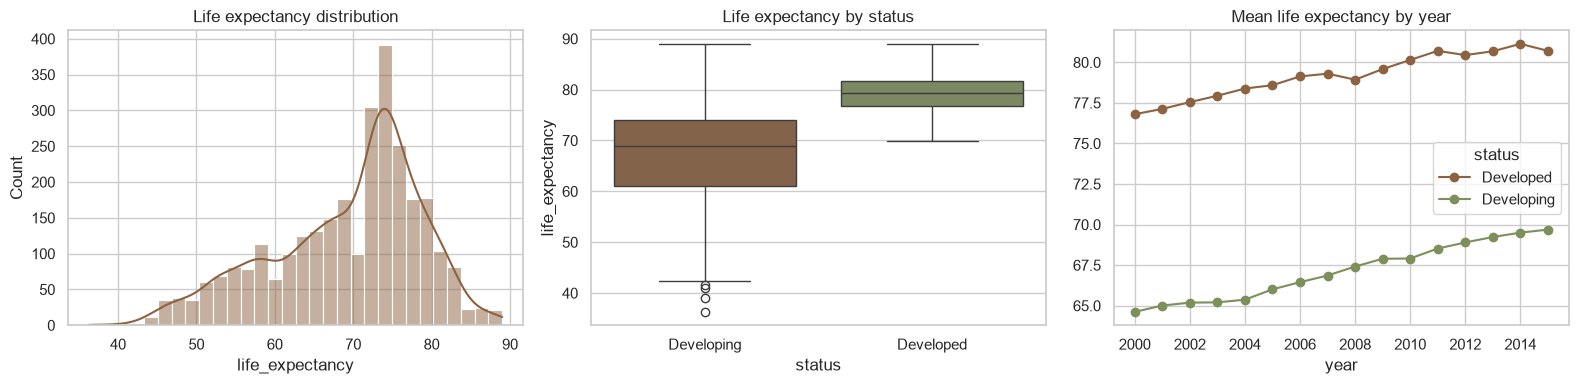

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df0["life_expectancy"], kde=True, ax=axes[0], color="#8c6240")
axes[0].set_title("Life expectancy distribution")
sns.boxplot(data=df0, x="status", y="life_expectancy", ax=axes[1], palette=["#8c6240", "#7d8f5a"])
axes[1].set_title("Life expectancy by status")
df0.groupby(["year", "status"])["life_expectancy"].mean().unstack().plot(ax=axes[2], marker="o")
axes[2].set_title("Mean life expectancy by year")
plt.tight_layout()
plt.savefig(ASSETS / "eda_target.png", dpi=120)
plt.show()

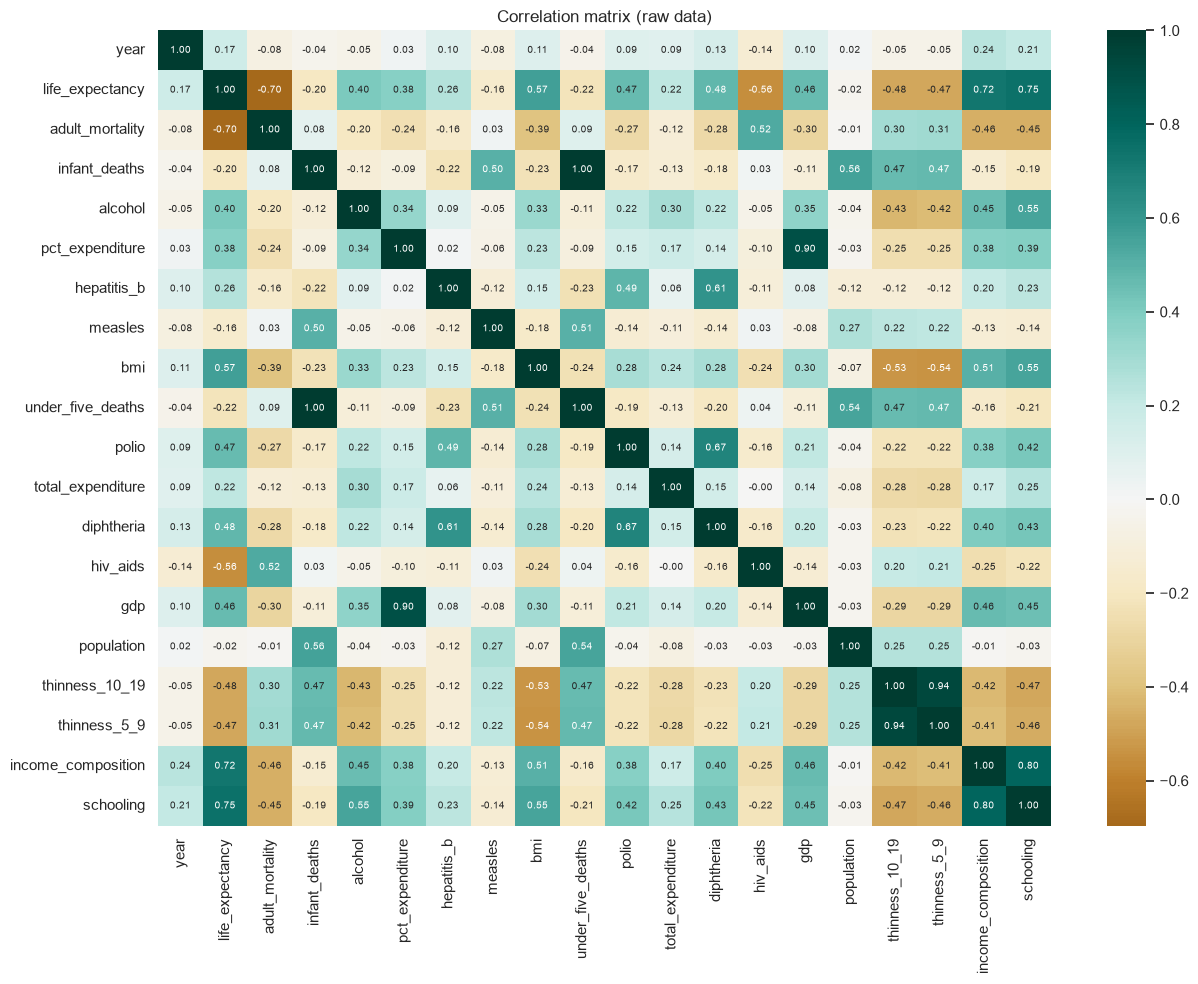

adult_mortality      -0.696359
hiv_aids             -0.556556
thinness_10_19       -0.477183
thinness_5_9         -0.471584
under_five_deaths    -0.222529
infant_deaths        -0.196557
measles              -0.157586
population           -0.021538
year                  0.170033
total_expenditure     0.218086
hepatitis_b           0.256762
pct_expenditure       0.381864
alcohol               0.404877
gdp                   0.461455
polio                 0.465556
diphtheria            0.479495
bmi                   0.567694
income_composition    0.724776
schooling             0.751975
Name: life_expectancy, dtype: float64

In [7]:
corr = df0.select_dtypes("number").corr()
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="BrBG", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation matrix (raw data)")
plt.tight_layout()
plt.savefig(ASSETS / "eda_corr_heatmap.png", dpi=120)
plt.show()
corr["life_expectancy"].drop("life_expectancy").sort_values()

與平均壽命相關性最強的是 **受教育年數 (+0.75)**、**收入組成 (+0.72)**、**成人死亡率 (−0.70)**、**HIV/AIDS (−0.56)**。
另外有幾組特徵彼此高度相關（`infant_deaths`↔`under_five_deaths` ≈ 0.997、`thinness_10_19`↔`thinness_5_9` ≈ 0.94、`pct_expenditure`↔`gdp` ≈ 0.90），
之後要用 VIF 檢查多重共線性。

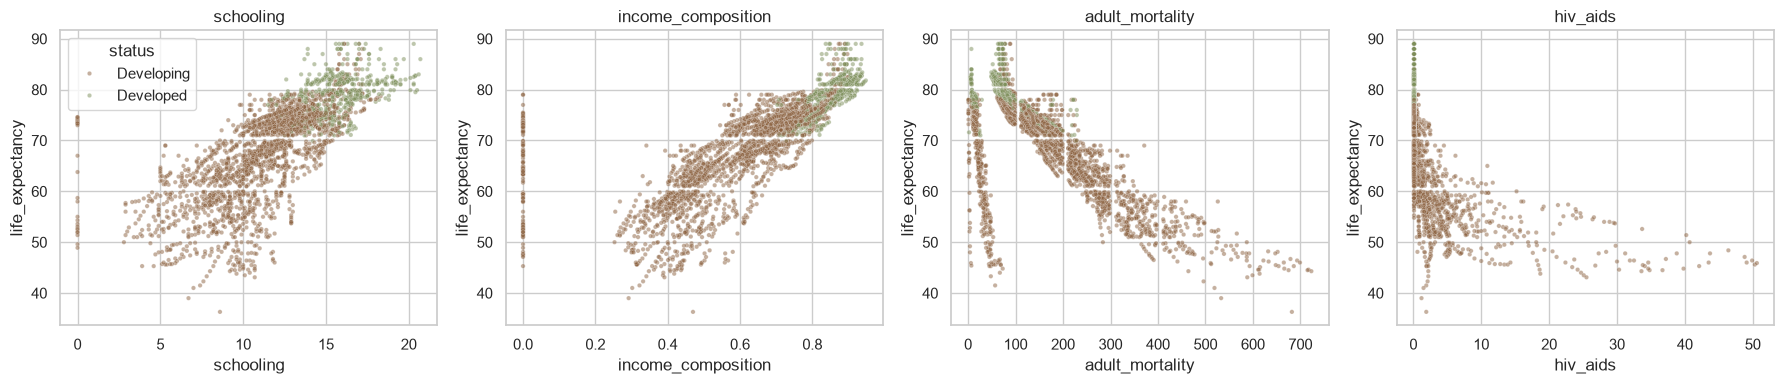

In [8]:
top = ["schooling", "income_composition", "adult_mortality", "hiv_aids"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, top):
    sns.scatterplot(data=df0, x=c, y="life_expectancy", hue="status", s=10, alpha=0.5, ax=ax, legend=(c == top[0]))
    ax.set_title(c)
plt.tight_layout()
plt.savefig(ASSETS / "eda_scatter_top.png", dpi=120)
plt.show()

## 3. Data Preparation（資料準備）

1. `status` → 二元變數 `developed`（1 = Developed）
2. `income_composition == 0`、`schooling == 0` → 缺值
3. 右偏特徵做 `log1p` 轉換
4. 以 **國家分組** 切分 80% / 20%（`GroupShuffleSplit`），測試集全為「模型沒看過的國家」
5. 缺值以 **訓練集中位數** 補值、標準化只在訓練集 fit（包在 Pipeline 內，交叉驗證時每折各自 fit，避免洩漏）

In [9]:
LOG_COLS = ["infant_deaths", "pct_expenditure", "measles", "under_five_deaths", "hiv_aids", "gdp", "population"]


def clean(d):
    d = d.copy()
    d["developed"] = (d["status"] == "Developed").astype(int)
    for c in ["income_composition", "schooling"]:
        d.loc[d[c] == 0, c] = np.nan
    return d.drop(columns="status")


def to_model_space(d):
    """把原始數值轉成模型使用的尺度（右偏欄位取 log1p）。"""
    d = d.copy()
    for c in LOG_COLS:
        if c in d:
            d[c] = np.log1p(d[c])
    return d


df_clean = clean(df0)          # 原始單位（部署時 UI 使用）
df = to_model_space(df_clean)  # 模型單位
pd.DataFrame({"skew_before": df_clean[LOG_COLS].skew(), "skew_after_log1p": df[LOG_COLS].skew()}).round(2)

,skew_before,skew_after_log1p
infant_deaths,9.79,0.70
pct_expenditure,4.65,-0.08
measles,9.44,0.56
under_five_deaths,9.50,0.65
hiv_aids,5.40,2.13
gdp,3.21,-0.14
population,15.92,-0.56


In [10]:
ALL_FEATURES = ["year", "developed", "adult_mortality", "infant_deaths", "alcohol", "pct_expenditure",
                "hepatitis_b", "measles", "bmi", "under_five_deaths", "polio", "total_expenditure",
                "diphtheria", "hiv_aids", "gdp", "population", "thinness_10_19", "thinness_5_9",
                "income_composition", "schooling"]
GKF = GroupKFold(n_splits=5)


def split_problem(target, features):
    d = df.dropna(subset=[target]).reset_index(drop=True)
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
    tr_idx, te_idx = next(gss.split(d, groups=d["country"]))
    # 依國家、年份排序，讓 Durbin-Watson 檢定有意義
    tr = d.iloc[tr_idx].sort_values(["country", "year"]).reset_index(drop=True)
    te = d.iloc[te_idx].sort_values(["country", "year"]).reset_index(drop=True)
    return d, tr, te


P1_TARGET = "life_expectancy"
P1_FEATURES = ALL_FEATURES
d1, tr1, te1 = split_problem(P1_TARGET, P1_FEATURES)
print(f"Problem 1 特徵數: {len(P1_FEATURES)}")
print(f"可用筆數 {len(d1)} → train {len(tr1)} 筆 / {tr1.country.nunique()} 國, test {len(te1)} 筆 / {te1.country.nunique()} 國")
print("train/test 國家重疊:", len(set(tr1.country) & set(te1.country)))

Problem 1 特徵數: 20
可用筆數 2928 → train 2336 筆 / 146 國, test 592 筆 / 37 國
train/test 國家重疊: 0


## 4. Modeling（建模）

### 4.1 特徵選擇（Feature Selection）— 只使用訓練資料

比較 5 種方法，每種方法產生一個特徵「排序」，再以 **GroupKFold(5) 交叉驗證 RMSE** 評估前 k 個特徵（k = 1…20）：

| 方法 | 類型 | 排序依據 |
|---|---|---|
| SelectKBest (f_regression) | Filter | 單變量 F 統計量 |
| RFE | Wrapper | 遞迴刪除最小 |係數| 的特徵 |
| Sequential Feature Selection (forward) | Wrapper | 每步加入讓 CV RMSE 最低的特徵 |
| Lasso path | Embedded | 特徵在 Lasso 路徑上「進入模型」的順序 |
| Permutation importance | Model-agnostic | 打亂該特徵後 RMSE 上升量 |

選擇規則（**精簡容忍度 1%**）：在所有 (方法, k) 中，選 CV RMSE 不超過「最佳值 × 1.01」、且 **k 最小** 的組合 —— 兼顧準確度與精簡。
（也試過 1-SE rule，但以國家分組的 CV 標準誤很大，會只留下 1–3 個特徵、測試集 R² 明顯下降，因此不採用。）
再以 **VIF > 10** 迭代剔除共線特徵。

In [11]:
def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))


def metrics(y, p, k):
    n, r2 = len(y), r2_score(y, p)
    return {"MAE": mean_absolute_error(y, p), "MSE": mean_squared_error(y, p), "RMSE": rmse(y, p),
            "R2": r2, "AdjR2": 1 - (1 - r2) * (n - 1) / (n - k - 1)}


def lr_pipe():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression())


def cv_rmse(X, y, groups, cols):
    s = -cross_val_score(lr_pipe(), X[cols], y, groups=groups, cv=GKF, scoring="neg_root_mean_squared_error")
    return float(s.mean()), float(s.std(ddof=1) / np.sqrt(len(s)))


def feature_rankings(X, y, groups):
    cols = list(X.columns)
    Z = SimpleImputer(strategy="median").fit_transform(X)
    Z = StandardScaler().fit_transform(Z)
    r = {}

    F, _ = f_regression(Z, y)
    r["SelectKBest"] = [cols[i] for i in np.argsort(-F)]

    rfe = RFE(LinearRegression(), n_features_to_select=1).fit(Z, y)
    r["RFE"] = [cols[i] for i in np.argsort(rfe.ranking_)]

    chosen, remaining = [], cols.copy()
    while remaining:
        scores = {c: cv_rmse(X, y, groups, chosen + [c])[0] for c in remaining}
        best = min(scores, key=scores.get)
        chosen.append(best)
        remaining.remove(best)
    r["SFS (forward)"] = chosen

    yc = np.asarray(y) - np.mean(y)
    a_max = np.abs(Z.T @ yc).max() / len(yc)
    alphas, coefs, _ = lasso_path(Z, yc, alphas=np.geomspace(a_max, a_max * 1e-4, 300))
    active = np.abs(coefs) > 1e-10
    entry = [np.argmax(row) if row.any() else len(alphas) for row in active]
    r["Lasso path"] = [cols[i] for i in np.argsort(entry, kind="stable")]

    lr = LinearRegression().fit(Z, y)
    pi = permutation_importance(lr, Z, y, n_repeats=10, random_state=SEED, scoring="neg_root_mean_squared_error")
    r["Permutation"] = [cols[i] for i in np.argsort(-pi.importances_mean)]
    return r


def selection_curves(X, y, groups, rankings):
    p = X.shape[1]
    return {m: [cv_rmse(X, y, groups, rank[:k]) for k in range(1, p + 1)] for m, rank in rankings.items()}


def vif_table(X):
    Xc = sm.add_constant(X, has_constant="add").values
    return pd.Series([variance_inflation_factor(Xc, i) for i in range(1, Xc.shape[1])], index=X.columns)


def choose_features(X, rankings, curves, tol=0.01, vif_thr=10.0):
    p = X.shape[1]
    grid = [(m, k, *curves[m][k - 1]) for m in curves for k in range(1, p + 1)]
    best = min(grid, key=lambda t: t[2])
    threshold = best[2] * (1 + tol)
    k_sel, _, m_sel = min((k, r, m) for m, k, r, _ in grid if r <= threshold)
    cols = rankings[m_sel][:k_sel]

    X_imp = X.fillna(X.median())
    dropped = []
    while True:
        v = vif_table(X_imp[cols])
        if v.max() <= vif_thr:
            break
        dropped.append((v.idxmax(), float(v.max())))
        cols = [c for c in cols if c != v.idxmax()]
    return {"best": best, "threshold": threshold, "method": m_sel, "k": k_sel,
            "vif_dropped": dropped, "selected": cols, "vif": v}


def plot_curves(curves, choice, tag, title):
    plt.figure(figsize=(10, 5))
    for m, vals in curves.items():
        ks = np.arange(1, len(vals) + 1)
        plt.plot(ks, [v[0] for v in vals], marker="o", ms=3, label=m)
    plt.axhline(choice["threshold"], color="gray", ls="--", lw=1, label="best × 1.01")
    plt.axvline(choice["k"], color="#a8442f", ls=":", lw=1, label=f"chosen k={choice['k']} ({choice['method']})")
    plt.xlabel("number of features k")
    plt.ylabel("GroupKFold CV RMSE")
    plt.title(title)
    plt.xticks(range(1, len(next(iter(curves.values()))) + 1))
    plt.legend()
    plt.tight_layout()
    plt.savefig(ASSETS / f"{tag}_feature_selection.png", dpi=120)
    plt.show()

In [12]:
X1tr, y1tr, g1tr = tr1[P1_FEATURES], tr1[P1_TARGET], tr1["country"]
X1te, y1te = te1[P1_FEATURES], te1[P1_TARGET]

rank1 = feature_rankings(X1tr, y1tr, g1tr)
pd.DataFrame(rank1, index=pd.RangeIndex(1, len(P1_FEATURES) + 1, name="rank"))

,SelectKBest,RFE,SFS (forward),Lasso path,Permutation
rank,,,,,
1,income_composition,under_five_deaths,income_composition,income_composition,under_five_deaths
2,schooling,infant_deaths,hiv_aids,hiv_aids,infant_deaths
3,hiv_aids,income_composition,adult_mortality,adult_mortality,income_composition
4,adult_mortality,hiv_aids,polio,schooling,hiv_aids
5,under_five_deaths,adult_mortality,under_five_deaths,under_five_deaths,adult_mortality
6,infant_deaths,schooling,infant_deaths,diphtheria,diphtheria
7,gdp,diphtheria,diphtheria,polio,schooling
8,bmi,developed,hepatitis_b,developed,polio
9,polio,polio,schooling,bmi,developed


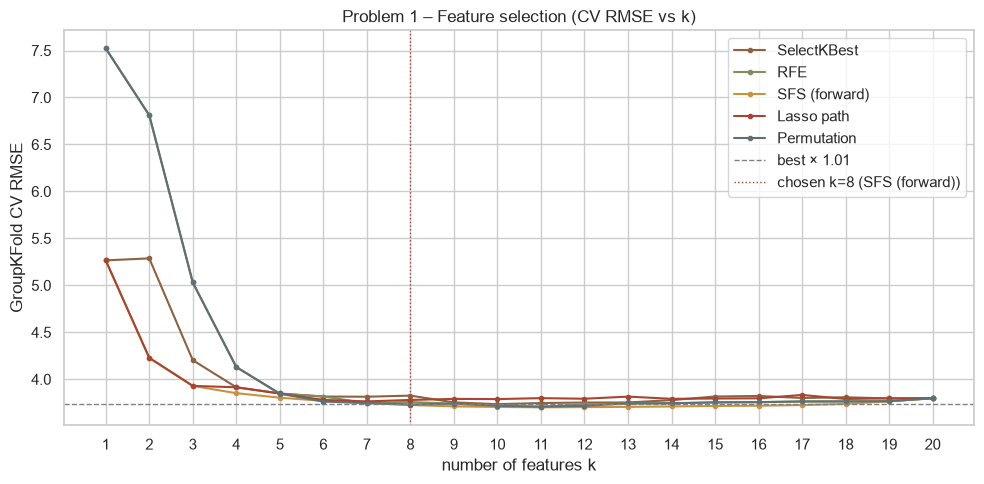

最佳: ('SFS (forward)', 11) RMSE=3.700 ± 0.229
1% 容忍度選擇: SFS (forward) k = 8
VIF 剔除: [('under_five_deaths', 197.5770556565066)]
最終特徵: ['income_composition', 'hiv_aids', 'adult_mortality', 'polio', 'infant_deaths', 'diphtheria', 'hepatitis_b']


,SelectKBest,RFE,SFS (forward),Lasso path,Permutation
1,5.265,7.522,5.265,5.265,7.522
3,4.202,5.030,3.929,3.929,5.030
5,3.848,3.846,3.803,3.848,3.846
8,3.825,3.757,3.725,3.779,3.730
10,3.734,3.718,3.705,3.788,3.718
12,3.752,3.732,3.703,3.792,3.717
15,3.816,3.753,3.715,3.794,3.753
20,3.797,3.797,3.797,3.797,3.797


In [13]:
curves1 = selection_curves(X1tr, y1tr, g1tr, rank1)
choice1 = choose_features(X1tr, rank1, curves1)
plot_curves(curves1, choice1, "p1", "Problem 1 – Feature selection (CV RMSE vs k)")

curve_tbl = pd.DataFrame({m: [v[0] for v in vals] for m, vals in curves1.items()}, index=range(1, len(P1_FEATURES) + 1))
print("最佳:", choice1["best"][:2], f"RMSE={choice1['best'][2]:.3f} ± {choice1['best'][3]:.3f}")
print("1% 容忍度選擇:", choice1["method"], "k =", choice1["k"])
print("VIF 剔除:", choice1["vif_dropped"])
print("最終特徵:", choice1["selected"])
curve_tbl.loc[[1, 3, 5, 8, 10, 12, 15, 20]].round(3)

In [14]:
choice1["vif"].round(2).sort_values(ascending=False).to_frame("VIF (selected)")

,VIF (selected)
income_composition,2.33
diphtheria,2.24
polio,2.18
hiv_aids,2.00
adult_mortality,1.84
infant_deaths,1.66
hepatitis_b,1.28


### 4.2 模型訓練與比較

| 模型 | 特徵 |
|---|---|
| Baseline：簡單線性回歸 | 訓練集上相關性最高的 1 個特徵 |
| OLS（全部特徵） | 20 |
| **OLS（特徵選擇後）** | 上面選出的特徵 |
| RidgeCV（全部特徵） | 20，L2 正則化，α 由 CV 選 |
| LassoCV（全部特徵） | 20，L1 正則化，α 由 GroupKFold CV 選 |

In [15]:
def compare_models(Xtr, ytr, gtr, Xte, yte, features, selected):
    corr_tr = Xtr.fillna(Xtr.median()).corrwith(ytr).abs()
    base_col = corr_tr.idxmax()
    folds = list(GKF.split(Xtr, ytr, gtr))
    candidates = [
        (f"Baseline simple LR ({base_col})", lr_pipe(), [base_col]),
        ("OLS – all features", lr_pipe(), features),
        ("OLS – selected features", lr_pipe(), selected),
        ("RidgeCV – all features",
         make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 61))), features),
        ("LassoCV – all features",
         make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LassoCV(cv=folds, max_iter=50000, random_state=SEED)), features),
    ]
    rows, fitted = [], {}
    for name, model, cols in candidates:
        model.fit(Xtr[cols], ytr)
        m_tr = metrics(ytr, model.predict(Xtr[cols]), len(cols))
        m_te = metrics(yte, model.predict(Xte[cols]), len(cols))
        rows.append({"Model": name, "k": len(cols), "Train R2": m_tr["R2"], **m_te})
        fitted[name] = model
    return pd.DataFrame(rows), fitted


res1, fitted1 = compare_models(X1tr, y1tr, g1tr, X1te, y1te, P1_FEATURES, choice1["selected"])
res1.round(4)

,Model,k,Train R2,MAE,MSE,RMSE,R2,AdjR2
0,Baseline simple LR (income_composition),1,0.6926,4.6837,43.5262,6.5974,0.5341,0.5334
1,OLS – all features,20,0.8623,2.8836,14.4740,3.8045,0.8451,0.8397
2,OLS – selected features,7,0.8503,3.0917,17.7052,4.2077,0.8105,0.8082
3,RidgeCV – all features,20,0.8623,2.8816,14.4627,3.8030,0.8452,0.8398
4,LassoCV – all features,20,0.8618,2.8473,14.3139,3.7834,0.8468,0.8414


In [16]:
lasso1 = fitted1["LassoCV – all features"][-1]
ridge1 = fitted1["RidgeCV – all features"][-1]
coef_cmp = pd.DataFrame({
    "OLS(all, std)": fitted1["OLS – all features"][-1].coef_,
    "Ridge(std)": ridge1.coef_,
    "Lasso(std)": lasso1.coef_,
}, index=P1_FEATURES)
print(f"Ridge α = {ridge1.alpha_:.3g}, Lasso α = {lasso1.alpha_:.3g}, Lasso 歸零特徵數 = {(lasso1.coef_ == 0).sum()}")
coef_cmp.round(3).sort_values("OLS(all, std)")

Ridge α = 0.1, Lasso α = 0.00784, Lasso 歸零特徵數 = 1


,"OLS(all, std)",Ridge(std),Lasso(std)
under_five_deaths,-8.402,-8.272,-5.326
hiv_aids,-2.538,-2.541,-2.607
adult_mortality,-1.974,-1.974,-1.987
hepatitis_b,-0.444,-0.444,-0.446
thinness_10_19,-0.081,-0.082,-0.002
alcohol,0.040,0.040,0.026
gdp,0.053,0.053,0.055
thinness_5_9,0.061,0.062,0.000
measles,0.089,0.089,0.067
bmi,0.152,0.153,0.159


## 5. Evaluation（評估）

### 5.1 statsmodels OLS（選擇後特徵）與 95% 信賴區間 / 預測區間

- **信賴區間 (CI)**：給定 x，**平均** y 的不確定性 → 較窄
- **預測區間 (PI)**：給定 x，**單一新觀測值** y 的不確定性（多加了殘差變異 σ²）→ 較寬

$$\hat y_0 \pm t_{0.975,\,n-p-1}\sqrt{\hat\sigma^2\,x_0^\top (X^\top X)^{-1}x_0}\quad\text{(CI)}\qquad
  \hat y_0 \pm t_{0.975,\,n-p-1}\sqrt{\hat\sigma^2\left(1 + x_0^\top (X^\top X)^{-1}x_0\right)}\quad\text{(PI)}$$

In [17]:
def design(X, cols, med):
    return sm.add_constant(X[cols].fillna(med[cols]), has_constant="add")


def fit_ols(Xtr, ytr, cols):
    med = Xtr.median()
    return sm.OLS(ytr, design(Xtr, cols, med)).fit(), med


sel1 = choice1["selected"]
ols1, med1 = fit_ols(X1tr, y1tr, sel1)
print(ols1.summary())

                            OLS Regression Results                            
Dep. Variable:        life_expectancy   R-squared:                       0.850
Model:                            OLS   Adj. R-squared:                  0.850
Method:                 Least Squares   F-statistic:                     1889.
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        11:29:18   Log-Likelihood:                -6337.2
No. Observations:                2336   AIC:                         1.269e+04
Df Residuals:                    2328   BIC:                         1.274e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 53.9377      0

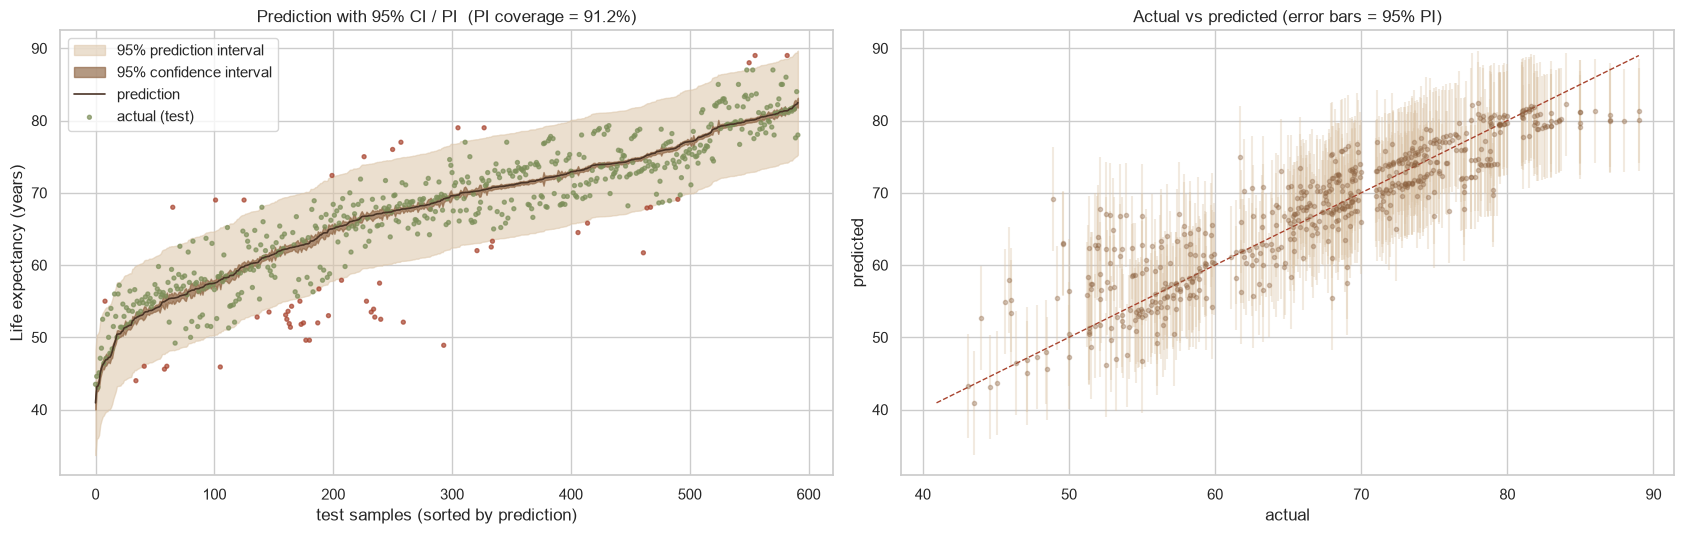

測試集 95% PI 實際覆蓋率: 91.22%
平均 PI 寬度: 14.36 歲, 平均 CI 寬度: 0.84 歲


,country,year,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper,actual,in_pi
0,Azerbaijan,2000,71.60,0.15,71.30,71.90,64.43,78.77,66.6,True
1,Azerbaijan,2001,69.60,0.11,69.38,69.82,62.43,76.77,67.5,True
2,Azerbaijan,2002,70.28,0.43,69.43,71.12,63.06,77.49,67.8,True
3,Azerbaijan,2003,71.09,0.15,70.81,71.38,63.92,78.26,67.8,True
4,Azerbaijan,2004,72.47,0.30,71.89,73.06,65.29,79.66,68.4,True
5,Azerbaijan,2005,71.44,0.15,71.15,71.74,64.27,78.61,68.4,True
6,Azerbaijan,2006,70.02,0.37,69.30,70.74,62.82,77.22,69.2,True
7,Azerbaijan,2007,74.76,0.15,74.46,75.05,67.59,81.93,73.0,True
8,Azerbaijan,2008,72.91,0.11,72.70,73.13,65.75,80.08,73.0,True
9,Azerbaijan,2009,73.14,0.10,72.95,73.34,65.98,80.31,78.0,True


In [18]:
def interval_frame(ols, Xte, yte, cols, med, meta):
    pf = ols.get_prediction(design(Xte, cols, med)).summary_frame(alpha=0.05)
    out = pd.concat([meta.reset_index(drop=True), pf.reset_index(drop=True)], axis=1)
    out["actual"] = yte.values
    out["in_pi"] = (out.actual >= out.obs_ci_lower) & (out.actual <= out.obs_ci_upper)
    return out


def plot_intervals(iv, target_label, tag):
    s = iv.sort_values("mean").reset_index(drop=True)
    x = np.arange(len(s))
    fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
    ax = axes[0]
    ax.fill_between(x, s.obs_ci_lower, s.obs_ci_upper, color="#dcc5a8", alpha=0.55, label="95% prediction interval")
    ax.fill_between(x, s.mean_ci_lower, s.mean_ci_upper, color="#8c6240", alpha=0.65, label="95% confidence interval")
    ax.plot(x, s["mean"], color="#4a3426", lw=1.2, label="prediction")
    ax.scatter(x, s.actual, s=8, c=np.where(s.in_pi, "#7d8f5a", "#a8442f"), alpha=0.7, label="actual (test)")
    ax.set_xlabel("test samples (sorted by prediction)")
    ax.set_ylabel(target_label)
    ax.set_title(f"Prediction with 95% CI / PI  (PI coverage = {iv.in_pi.mean():.1%})")
    ax.legend(loc="upper left")
    ax = axes[1]
    lo, hi = min(s.actual.min(), s["mean"].min()), max(s.actual.max(), s["mean"].max())
    ax.errorbar(s.actual, s["mean"], yerr=[s["mean"] - s.obs_ci_lower, s.obs_ci_upper - s["mean"]],
                fmt="o", ms=3, alpha=0.35, ecolor="#dcc5a8", color="#8c6240")
    ax.plot([lo, hi], [lo, hi], "--", color="#a8442f", lw=1)
    ax.set_xlabel("actual")
    ax.set_ylabel("predicted")
    ax.set_title("Actual vs predicted (error bars = 95% PI)")
    plt.tight_layout()
    plt.savefig(ASSETS / f"{tag}_prediction_intervals.png", dpi=120)
    plt.show()


iv1 = interval_frame(ols1, X1te, y1te, sel1, med1, te1[["country", "year"]])
plot_intervals(iv1, "Life expectancy (years)", "p1")
print(f"測試集 95% PI 實際覆蓋率: {iv1.in_pi.mean():.2%}")
print(f"平均 PI 寬度: {(iv1.obs_ci_upper - iv1.obs_ci_lower).mean():.2f} 歲, 平均 CI 寬度: {(iv1.mean_ci_upper - iv1.mean_ci_lower).mean():.2f} 歲")
iv1.head(10).round(2)

### 5.2 五大回歸假設檢驗

| 假設 | 檢驗方式 |
|---|---|
| 1. 線性 (Linearity) | 殘差 vs 預測值圖、Rainbow test |
| 2. 誤差獨立 (Independence) | Durbin-Watson（資料依國家、年份排序） |
| 3. 同質變異 (Homoscedasticity) | Breusch-Pagan test、Scale-Location 圖 |
| 4. 誤差常態 (Normality) | Jarque-Bera test、Q-Q plot |
| 5. 無多重共線性 (No multicollinearity) | VIF（< 10） |

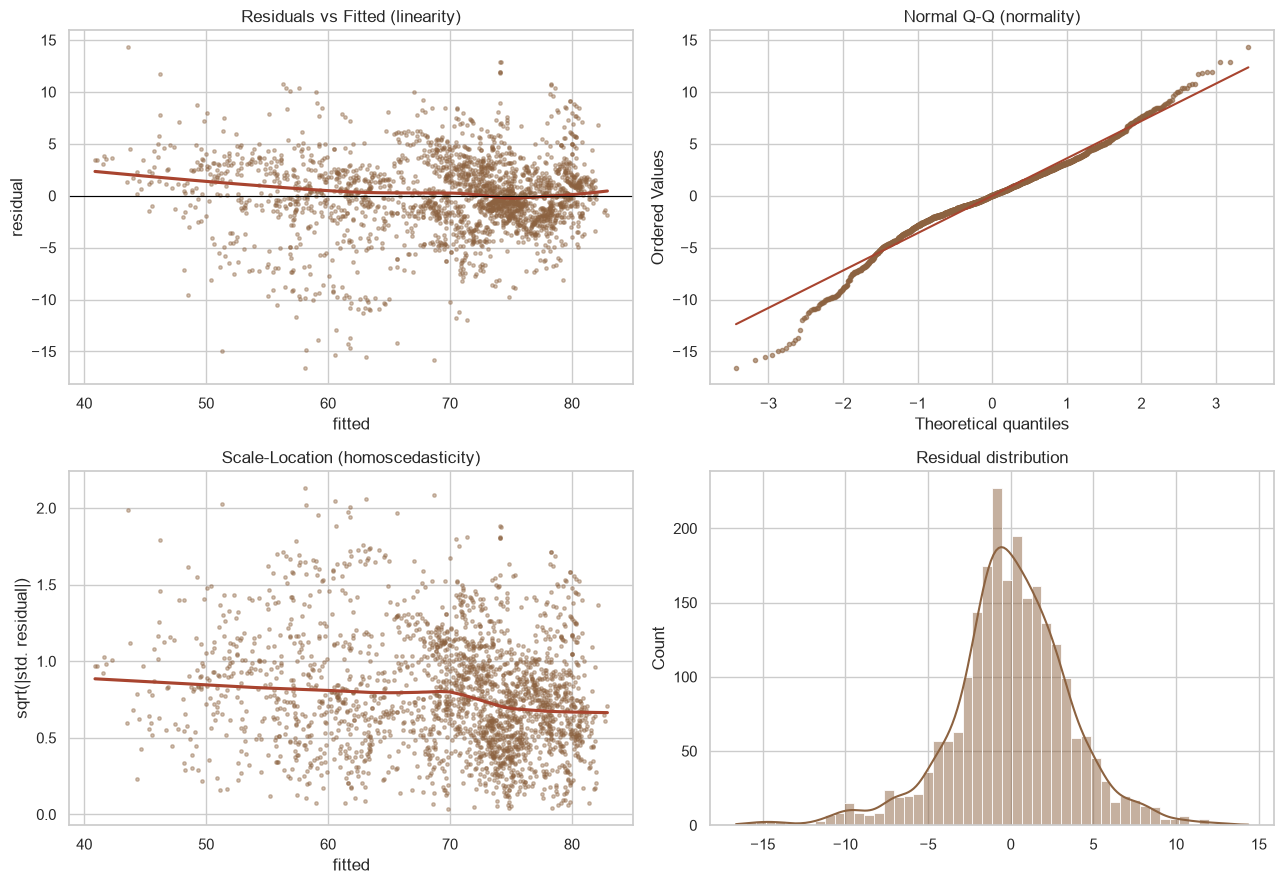

,assumption,test,statistic,p_value,pass
0,1. Linearity,Rainbow,1.1587,0.006,False
1,2. Independence,Durbin-Watson (ideal≈2),0.6350,NaN,False
2,3. Homoscedasticity,Breusch-Pagan,190.2655,0.000,False
3,4. Normality,Jarque-Bera,414.7746,0.000,False
4,5. No multicollinearity,max VIF (<10),2.3337,NaN,True


In [19]:
def assumption_checks(ols, X_imp_sel):
    resid, fitted = ols.resid, ols.fittedvalues
    rain_f, rain_p = linear_rainbow(ols)
    dw = durbin_watson(resid)
    bp_lm, bp_p, _, _ = het_breuschpagan(resid, ols.model.exog)
    jb_stat, jb_p = stats.jarque_bera(resid)
    vif = vif_table(X_imp_sel)
    return pd.DataFrame([
        {"assumption": "1. Linearity", "test": "Rainbow", "statistic": rain_f, "p_value": rain_p,
         "pass": rain_p > 0.05},
        {"assumption": "2. Independence", "test": "Durbin-Watson (ideal≈2)", "statistic": dw, "p_value": np.nan,
         "pass": 1.5 < dw < 2.5},
        {"assumption": "3. Homoscedasticity", "test": "Breusch-Pagan", "statistic": bp_lm, "p_value": bp_p,
         "pass": bp_p > 0.05},
        {"assumption": "4. Normality", "test": "Jarque-Bera", "statistic": jb_stat, "p_value": jb_p,
         "pass": jb_p > 0.05},
        {"assumption": "5. No multicollinearity", "test": "max VIF (<10)", "statistic": vif.max(), "p_value": np.nan,
         "pass": vif.max() < 10},
    ])


def plot_residuals(ols, tag):
    resid, fitted = ols.resid, ols.fittedvalues
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    sns.regplot(x=fitted, y=resid, lowess=True, scatter_kws={"s": 6, "alpha": 0.4},
                line_kws={"color": "#a8442f"}, ax=axes[0, 0])
    axes[0, 0].axhline(0, color="k", lw=0.8)
    axes[0, 0].set(title="Residuals vs Fitted (linearity)", xlabel="fitted", ylabel="residual")
    stats.probplot(resid, dist="norm", plot=axes[0, 1])
    pts, fit_line = axes[0, 1].get_lines()[:2]
    pts.set(markerfacecolor="#8c6240", markeredgecolor="#8c6240", markersize=3, alpha=0.6)
    fit_line.set_color("#a8442f")
    axes[0, 1].set_title("Normal Q-Q (normality)")
    sns.regplot(x=fitted, y=np.sqrt(np.abs(resid / resid.std())), lowess=True,
                scatter_kws={"s": 6, "alpha": 0.4}, line_kws={"color": "#a8442f"}, ax=axes[1, 0])
    axes[1, 0].set(title="Scale-Location (homoscedasticity)", xlabel="fitted", ylabel="sqrt(|std. residual|)")
    sns.histplot(resid, kde=True, ax=axes[1, 1])
    axes[1, 1].set_title("Residual distribution")
    plt.tight_layout()
    plt.savefig(ASSETS / f"{tag}_residual_diagnostics.png", dpi=120)
    plt.show()


asm1 = assumption_checks(ols1, X1tr[sel1].fillna(med1[sel1]))
plot_residuals(ols1, "p1")
asm1.round(4)

**解讀**：在 2,300 筆左右的大樣本下，正式檢定幾乎一定會拒絕「完美常態 / 完美同質變異」，所以要搭配圖形判斷。
最需要注意的是 **獨立性**：同一國家連續年份的誤差高度相關（DW 遠小於 2），這是 panel data 的本質。
這不會讓係數估計產生偏誤，但會讓一般標準誤 **低估**，因此下面改用 **以國家為群集的穩健標準誤（cluster-robust SE）** 重新判斷顯著性。

In [20]:
def coef_table(ols, Xtr, ytr, cols, med, groups):
    cl = sm.OLS(ytr, design(Xtr, cols, med)).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(groups)[0]})
    return pd.DataFrame({"coef": ols.params, "se": ols.bse, "p": ols.pvalues,
                         "se_cluster": cl.bse, "p_cluster": cl.pvalues})


ct1 = coef_table(ols1, X1tr, y1tr, sel1, med1, g1tr)
ct1.round(4)

,coef,se,p,se_cluster,p_cluster
const,53.9377,0.6736,0.0,2.2517,0.0000
income_composition,26.9331,0.7558,0.0,3.0827,0.0000
hiv_aids,-3.4125,0.1441,0.0,0.3862,0.0000
adult_mortality,-0.0171,0.0008,0.0,0.0027,0.0000
polio,0.0251,0.0048,0.0,0.0086,0.0034
infant_deaths,-0.6073,0.0592,0.0,0.2177,0.0053
diphtheria,0.0370,0.0048,0.0,0.0092,0.0001
hepatitis_b,-0.0235,0.0038,0.0,0.0071,0.0009


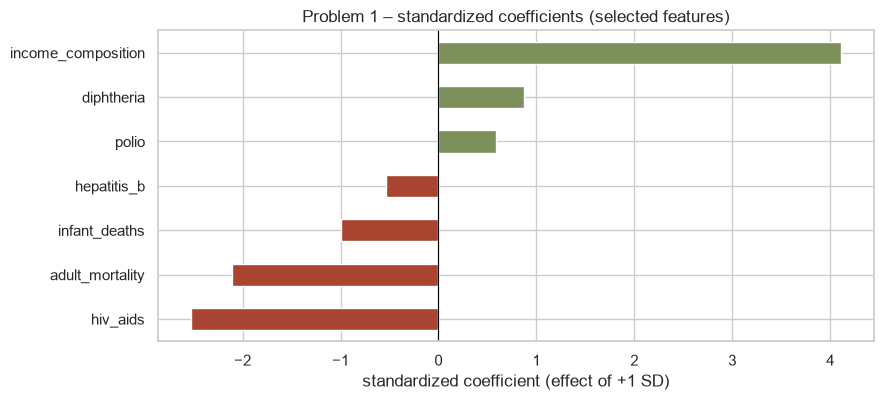

In [21]:
def plot_coefs(Xtr, ytr, cols, tag, title):
    m = lr_pipe().fit(Xtr[cols], ytr)
    s = pd.Series(m[-1].coef_, index=cols).sort_values()
    plt.figure(figsize=(9, 0.38 * len(cols) + 1.5))
    s.plot.barh(color=np.where(s > 0, "#7d8f5a", "#a8442f"))
    plt.axvline(0, color="k", lw=0.8)
    plt.title(title)
    plt.xlabel("standardized coefficient (effect of +1 SD)")
    plt.tight_layout()
    plt.savefig(ASSETS / f"{tag}_coefficients.png", dpi=120)
    plt.show()
    return s


std_coef1 = plot_coefs(X1tr, y1tr, sel1, "p1", "Problem 1 – standardized coefficients (selected features)")

## 6. Problem 2：成人死亡率（Adult Mortality）

使用完全相同的流程（分組切分 → 5 種特徵選擇 → 模型比較 → 區間 → 假設檢驗）。
特徵排除 `life_expectancy`（平均壽命是由死亡率計算出來的，放進來會造成目標洩漏），共 19 個特徵。

Problem 2 特徵數: 19 | train 2336 / test 592


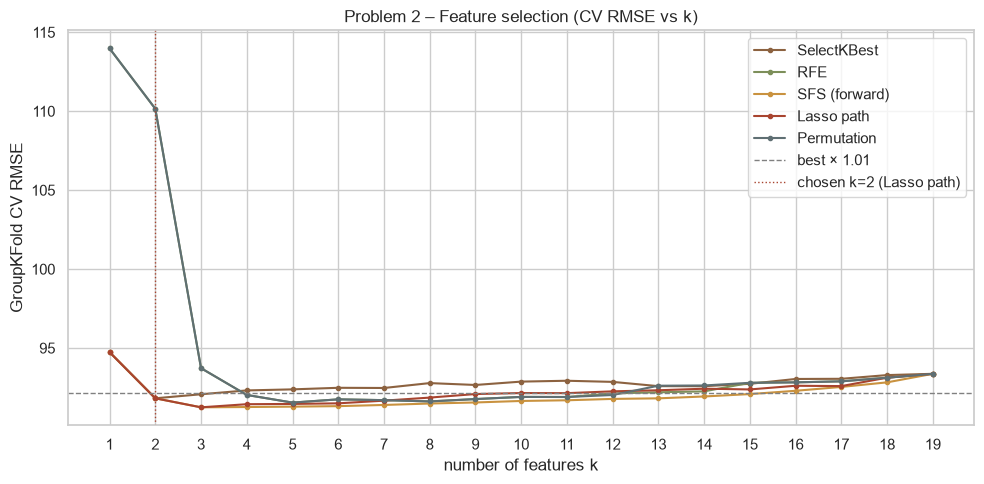

1% 容忍度選擇: Lasso path k = 2 | VIF 剔除: []
最終特徵: ['hiv_aids', 'income_composition']


In [22]:
P2_TARGET = "adult_mortality"
P2_FEATURES = [c for c in ALL_FEATURES if c != "adult_mortality"]
d2, tr2, te2 = split_problem(P2_TARGET, P2_FEATURES)
X2tr, y2tr, g2tr = tr2[P2_FEATURES], tr2[P2_TARGET], tr2["country"]
X2te, y2te = te2[P2_FEATURES], te2[P2_TARGET]
print(f"Problem 2 特徵數: {len(P2_FEATURES)} | train {len(tr2)} / test {len(te2)}")

rank2 = feature_rankings(X2tr, y2tr, g2tr)
curves2 = selection_curves(X2tr, y2tr, g2tr, rank2)
choice2 = choose_features(X2tr, rank2, curves2)
plot_curves(curves2, choice2, "p2", "Problem 2 – Feature selection (CV RMSE vs k)")
print("1% 容忍度選擇:", choice2["method"], "k =", choice2["k"], "| VIF 剔除:", choice2["vif_dropped"])
print("最終特徵:", choice2["selected"])

In [23]:
res2, fitted2 = compare_models(X2tr, y2tr, g2tr, X2te, y2te, P2_FEATURES, choice2["selected"])
res2.round(4)

,Model,k,Train R2,MAE,MSE,RMSE,R2,AdjR2
0,Baseline simple LR (hiv_aids),1,0.4106,76.4295,10372.1745,101.8439,0.3703,0.3692
1,OLS – all features,19,0.4744,67.3561,9459.0438,97.2576,0.4257,0.4067
2,OLS – selected features,2,0.4535,67.2134,9570.9219,97.8311,0.4190,0.4170
3,RidgeCV – all features,19,0.4743,67.2668,9449.1936,97.2070,0.4263,0.4073
4,LassoCV – all features,19,0.4618,68.6096,9386.7887,96.8854,0.4301,0.4112


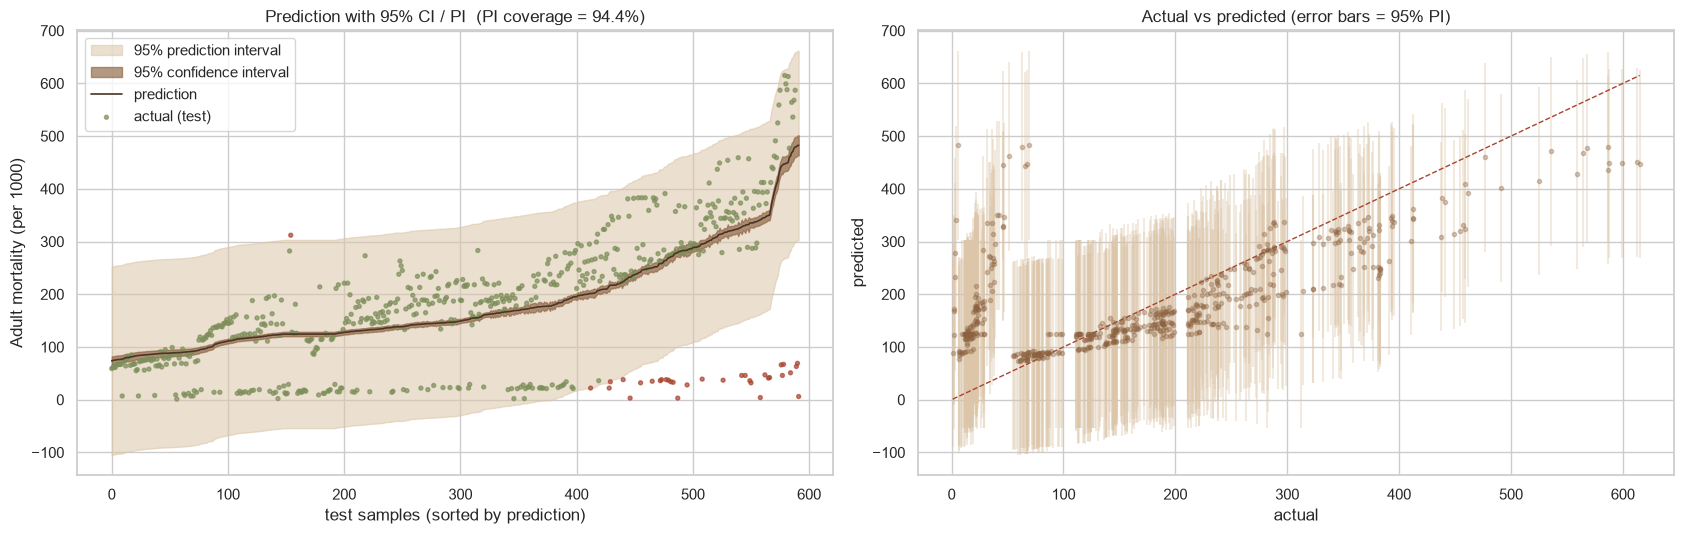

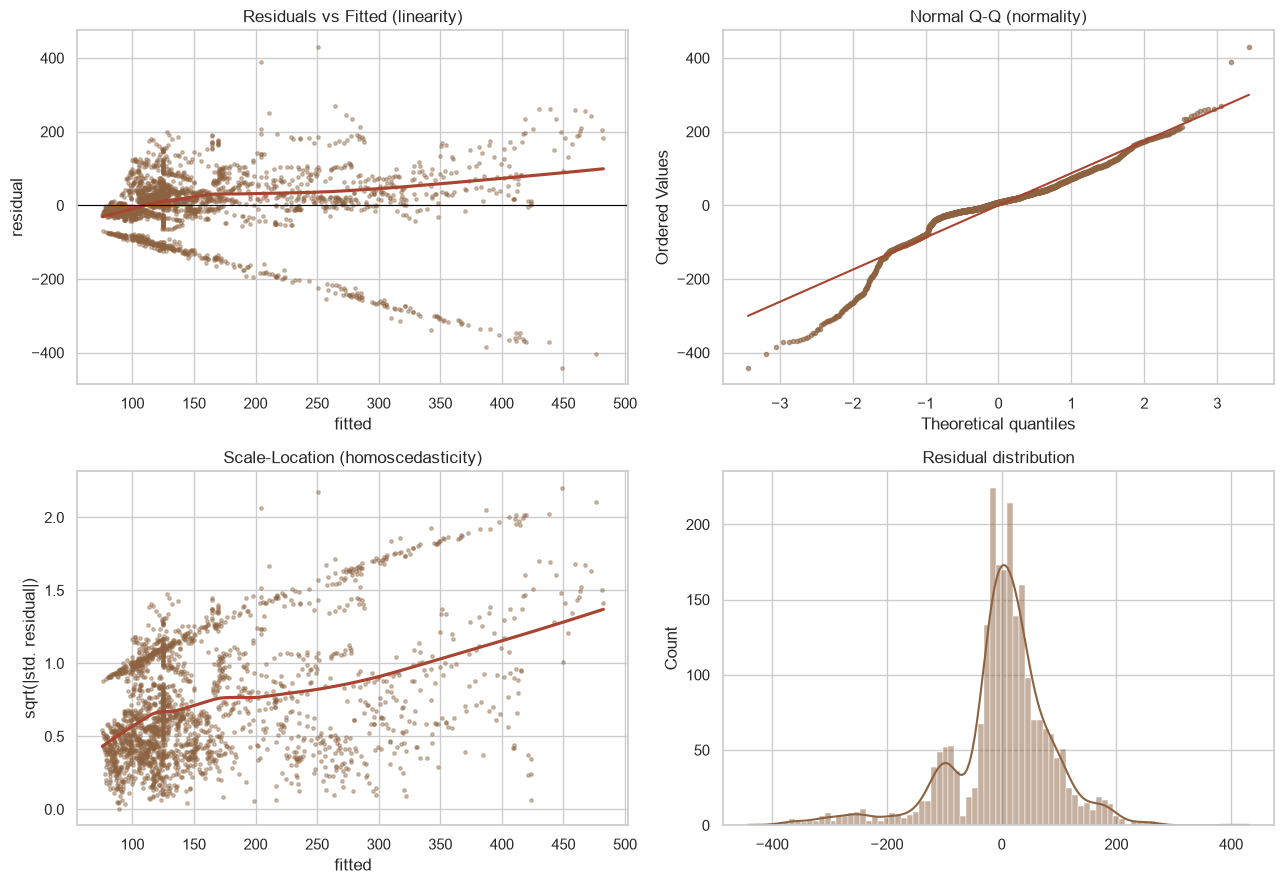

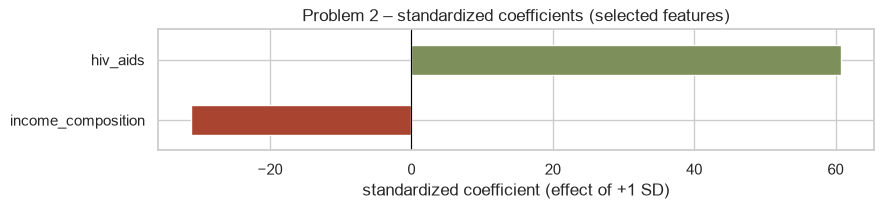

測試集 95% PI 覆蓋率: 94.43%


,assumption,test,statistic,p_value,pass
0,1. Linearity,Rainbow,1.1513,0.0081,False
1,2. Independence,Durbin-Watson (ideal≈2),1.1594,NaN,False
2,3. Homoscedasticity,Breusch-Pagan,556.6399,0.0000,False
3,4. Normality,Jarque-Bera,1355.2803,0.0000,False
4,5. No multicollinearity,max VIF (<10),1.5001,NaN,True


In [24]:
sel2 = choice2["selected"]
ols2, med2 = fit_ols(X2tr, y2tr, sel2)
iv2 = interval_frame(ols2, X2te, y2te, sel2, med2, te2[["country", "year"]])
plot_intervals(iv2, "Adult mortality (per 1000)", "p2")
asm2 = assumption_checks(ols2, X2tr[sel2].fillna(med2[sel2]))
plot_residuals(ols2, "p2")
std_coef2 = plot_coefs(X2tr, y2tr, sel2, "p2", "Problem 2 – standardized coefficients (selected features)")
ct2 = coef_table(ols2, X2tr, y2tr, sel2, med2, g2tr)
print(f"測試集 95% PI 覆蓋率: {iv2.in_pi.mean():.2%}")
asm2.round(4)

**Problem 2 小結**：成人死亡率的 R² 明顯低於平均壽命。原因是此欄位本身雜訊很大（例如有國家某些年份成人死亡率僅 1–10，明顯為登錄錯誤），
且殘差呈現強烈右偏與異質變異，線性模型的預測區間也因此較寬。這說明了「資料品質」對線性回歸的影響。

## 7. Deployment（部署）

1. 以 **全部資料**（train + test）重新估計最終 OLS 模型（特徵 = 特徵選擇的結果）
2. 匯出係數、共變異矩陣 $\hat\sigma^2 (X^\top X)^{-1}$、補值中位數、log 轉換設定 → `model/problem*.json`
3. 網頁（Vercel 靜態網站）讀取 JSON，在瀏覽器即時計算預測值與 95% 信賴 / 預測區間；評估圖表也由同一份 JSON 繪製

In [25]:
def jsonable(o):
    if isinstance(o, dict):
        return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [jsonable(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if not np.isfinite(o) else round(float(o), 6)
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, np.bool_):
        return bool(o)
    return o


def export_problem(key, title, target, unit, features, d, tr, te, rankings, curves, choice, res, iv, asm, ct, std_coef):
    sel = choice["selected"]
    X_all = d[sel]
    med_all = X_all.median()
    final = sm.OLS(d[target], design(d, sel, med_all)).fit()
    cov = final.cov_params().values
    raw_all = df_clean.loc[df_clean[target].notna()]

    feats = []
    for c in sel:
        col = raw_all[c]
        feats.append({
            "name": c, "label": LABELS[c], "log": c in LOG_COLS,
            "median": float(col.median()), "min": float(col.min()), "max": float(col.max()),
            "p01": float(col.quantile(0.01)), "p99": float(col.quantile(0.99)),
            "integer": c in ("year", "developed"),
        })

    presets = {}
    latest = raw_all.sort_values("year").groupby("country").tail(1)
    for _, row in latest.iterrows():
        presets[row["country"]] = {
            "year": int(row["year"]), "actual": float(row[target]),
            "values": {c: (float(row[c]) if pd.notna(row[c]) else float(raw_all[c].median())) for c in sel},
        }

    corr_target = d[features].corrwith(d[target]).sort_values()
    out = {
        "key": key, "title": title, "target": target, "target_label": LABELS[target], "unit": unit,
        "source": "https://www.kaggle.com/datasets/kumarajarshi/life-expectancy-who",
        "dataset": {"rows": len(d), "countries": int(d.country.nunique()),
                    "n_train": len(tr), "n_test": len(te),
                    "train_countries": int(tr.country.nunique()), "test_countries": int(te.country.nunique()),
                    "n_features": len(features)},
        "labels": {c: LABELS[c] for c in features + [target]},
        "corr": corr_target.to_dict(),
        "selection": {
            "rankings": rankings,
            "curves": {m: [{"k": i + 1, "rmse": v[0], "se": v[1]} for i, v in enumerate(vals)] for m, vals in curves.items()},
            "best": {"method": choice["best"][0], "k": choice["best"][1], "rmse": choice["best"][2], "se": choice["best"][3]},
            "threshold": choice["threshold"], "method": choice["method"], "k": choice["k"],
            "vif_dropped": [{"feature": f, "vif": v} for f, v in choice["vif_dropped"]],
            "selected": sel, "vif": choice["vif"].to_dict(),
        },
        "models": res.to_dict(orient="records"),
        "std_coef": std_coef.to_dict(),
        "intervals": {
            "coverage": float(iv.in_pi.mean()),
            "mean_pi_width": float((iv.obs_ci_upper - iv.obs_ci_lower).mean()),
            "mean_ci_width": float((iv.mean_ci_upper - iv.mean_ci_lower).mean()),
            "points": [{"country": r.country, "year": int(r.year), "actual": r.actual, "pred": r["mean"],
                        "ci": [r.mean_ci_lower, r.mean_ci_upper], "pi": [r.obs_ci_lower, r.obs_ci_upper]}
                       for _, r in iv.iterrows()],
        },
        "assumptions": asm.to_dict(orient="records"),
        "coef_table_train": [{"name": i, **r} for i, r in ct.to_dict(orient="index").items()],
        "final": {
            "features": feats, "params": final.params.values.tolist(), "names": ["const"] + sel,
            "cov": cov.tolist(), "sigma2": float(final.scale), "df_resid": float(final.df_resid),
            "t": float(stats.t.ppf(0.975, final.df_resid)), "r2": float(final.rsquared),
            "adj_r2": float(final.rsquared_adj), "n": int(final.nobs), "impute_median_model_space": med_all.to_dict(),
        },
        "presets": presets,
    }
    path = MODEL_DIR / f"{key}.json"
    path.write_text(json.dumps(jsonable(out), ensure_ascii=False), encoding="utf-8")
    print(f"saved {path.relative_to(ROOT)} ({path.stat().st_size / 1024:.0f} KB) | final R² (all data) = {final.rsquared:.4f}")
    return final


final1 = export_problem("problem1", "Problem 1：預測平均壽命", P1_TARGET, "歲", P1_FEATURES, d1, tr1, te1,
                        rank1, curves1, choice1, res1, iv1, asm1, ct1, std_coef1)
final2 = export_problem("problem2", "Problem 2：預測成人死亡率", P2_TARGET, "‰", P2_FEATURES, d2, tr2, te2,
                        rank2, curves2, choice2, res2, iv2, asm2, ct2, std_coef2)

saved model\problem1.json (129 KB) | final R² (all data) = 0.8476


saved model\problem2.json (111 KB) | final R² (all data) = 0.4485


### 7.1 只用 NumPy 的預測函式（與網頁上的 JavaScript 邏輯相同）

In [26]:
def predict_new(model_json, raw_values):
    """raw_values: {特徵: 原始單位數值}；回傳 (預測值, 95% CI, 95% PI)。"""
    f = model_json["final"]
    x = [1.0]
    for feat in f["features"]:
        v = raw_values.get(feat["name"], feat["median"])
        x.append(np.log1p(v) if feat["log"] else v)
    x = np.array(x)
    yhat = float(x @ np.array(f["params"]))
    se_mean = float(np.sqrt(x @ np.array(f["cov"]) @ x))
    se_pred = float(np.sqrt(f["sigma2"] + se_mean ** 2))
    t = f["t"]
    return yhat, (yhat - t * se_mean, yhat + t * se_mean), (yhat - t * se_pred, yhat + t * se_pred)


m1 = json.loads((MODEL_DIR / "problem1.json").read_text(encoding="utf-8"))
for country in ["Japan", "Brazil", "Nigeria"]:
    p = m1["presets"][country]
    yhat, ci, pi = predict_new(m1, p["values"])
    print(f"{country:8s} {p['year']}: 實際 {p['actual']:.1f} 歲 | 預測 {yhat:.1f} 歲, 95% CI [{ci[0]:.1f}, {ci[1]:.1f}], 95% PI [{pi[0]:.1f}, {pi[1]:.1f}]")

Japan    2015: 實際 83.7 歲 | 預測 79.8 歲, 95% CI [79.4, 80.1], 95% PI [72.5, 87.1]
Brazil   2015: 實際 75.0 歲 | 預測 72.9 歲, 95% CI [72.5, 73.3], 95% PI [65.6, 80.2]
Nigeria  2015: 實際 54.5 歲 | 預測 55.0 歲, 95% CI [54.3, 55.6], 95% PI [47.7, 62.3]


### 7.2 政策模擬（What-if）
以奈及利亞（Nigeria）為例：若受教育年數 +3 年、HIV/AIDS 死亡率減半，模型預期平均壽命會如何變化？

In [27]:
base = dict(m1["presets"]["Nigeria"]["values"])
scenario = dict(base)
for name, fn in [("schooling", lambda v: v + 3), ("hiv_aids", lambda v: v / 2)]:
    if name in scenario:
        scenario[name] = fn(scenario[name])
y0 = predict_new(m1, base)[0]
y1 = predict_new(m1, scenario)[0]
print(f"基準 {y0:.2f} 歲 → 情境 {y1:.2f} 歲（{y1 - y0:+.2f} 歲）")
print("（只有被選入模型的特徵會影響結果；這是相關性而非因果推論）")

基準 54.99 歲 → 情境 57.04 歲（+2.05 歲）
（只有被選入模型的特徵會影響結果；這是相關性而非因果推論）


## 8. 結論

結論數字見 README 與網頁；重點：

1. 以國家分組切分後，Problem 1 的多元線性回歸在**沒看過的國家**上仍有高解釋力，遠優於單一特徵的 baseline。
2. 5 種特徵選擇方法的曲線在 k ≈ 8–12 後趨於平緩，1-SE rule 可以用較少特徵達到幾乎相同的 RMSE，模型更好解釋。
3. Ridge / Lasso 與 OLS 表現幾乎相同 → 在此樣本量下過擬合不是主要問題，正則化的價值主要在處理共線性與自動選特徵。
4. 誤差獨立性被違反（panel data），因此係數顯著性以 cluster-robust SE 判斷；未來可改用固定效果 / 混合效果模型。
5. Problem 2（成人死亡率）解釋力較低，反映目標欄位的資料品質問題。